# MAP Matematica 6: Parte 2, CNN y comparacion
**Responsable:** Claudia (C). **Incisos:** 4 (CNN, ruido, limpieza) y 5 (comparacion).

Las funciones de FFT y filtros ya existen en `src/fft_nucleo.py` (Tony). Aqui solo se importan.

**Instrucciones:** Investigue sobre filtros de imagen basados en redes neuronales convolucionales (CNN). No es necesario que entrene una red desde cero. Busque un modelo pre-entrenado sencillo para una tarea como eliminación de ruido (denoising) y mejora de la resolución (superresolution). Bibliotecas como `TensorFlow/Keras' o `PyTorch' tienen tutoriales y modelos
disponibles.


In [55]:
#@INCLUIR: src/fft_nucleo.py
#(en el notebook final, la herramienta de union reemplaza esta celda por el codigo de src/fft_nucleo.py)
#ruta de la carpeta con el nucleo de la FFT
import sys
sys.path.append("../src")
#importacion de todas las funciones del nucleo
from fft_nucleo import *

In [56]:
#librerias para graficar
import numpy as np
import matplotlib.pyplot as plt
#carpeta con las imagenes del proyecto y carpeta de salida de figuras del reporte
CARPETA_IMAGENES = Path("../imagenes")
CARPETA_FIGURAS = Path("../reporte/figuras")
#se crea la carpeta de figuras si no existe
CARPETA_FIGURAS.mkdir(parents=True, exist_ok=True)
#PNG individuales de los incisos de CNN y comparacion.
CARPETA_CNN = CARPETA_FIGURAS / "cnn"
for inciso in ("4a", "4b", "4c", "4d", "5"):
    (CARPETA_CNN / inciso).mkdir(parents=True, exist_ok=True)
#tamano al que se ajustan las imagenes (potencia de 2, requisito de la FFT recursiva)
TAM = 256

## Carga de imagenes (misma logica que la parte 2 de Tony)

In [57]:
#lista de imagenes que hay en la carpeta del proyecto
rutas = listar_imagenes(CARPETA_IMAGENES)
#si hay imagenes se cargan en gris y ajustadas a TAM x TAM
if rutas:
    imagenes = {r.stem: cargar_imagen(r, TAM) for r in rutas}
#si no hay imagenes se usa la sintetica
else:
    imagenes = {"sintetica": imagen_sintetica(TAM)}
    print("AVISO: no hay imagenes en ../imagenes, se usa la imagen sintetica de respaldo")

## Inciso 4a. Modelo CNN preentrenado

Agregue su implementación y utilícela para las imágenes adjuntas en el proyecto.


Modelo: dncnn_gray_blind (KAIR v1.0) | PyTorch: 2.14.1+cpu
Dispositivo: cpu | Pesos: C:\Users\mclai\Documents\GALILEO\6SEMESTRE\Matematica\final_proj_mate_6\herramientas\model_zoo\dncnn_gray_blind.pth
SHA-256: cc2ac7fa2f248a7f7a3da414a848326634511ec8b5adb7799e857ed788067bfe


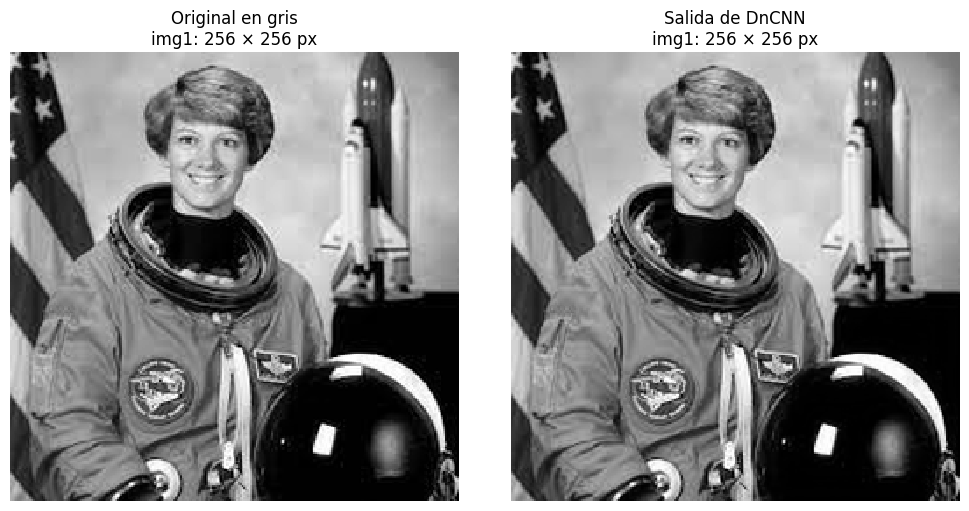

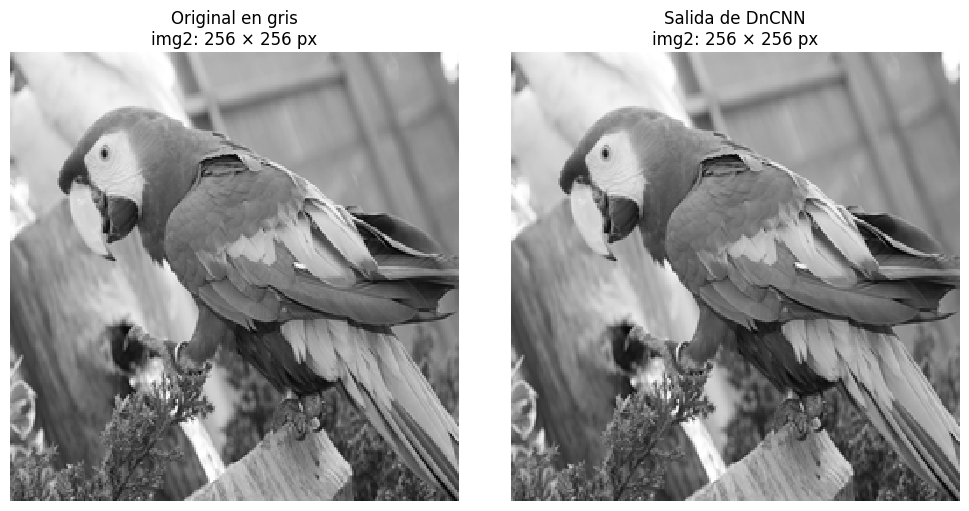

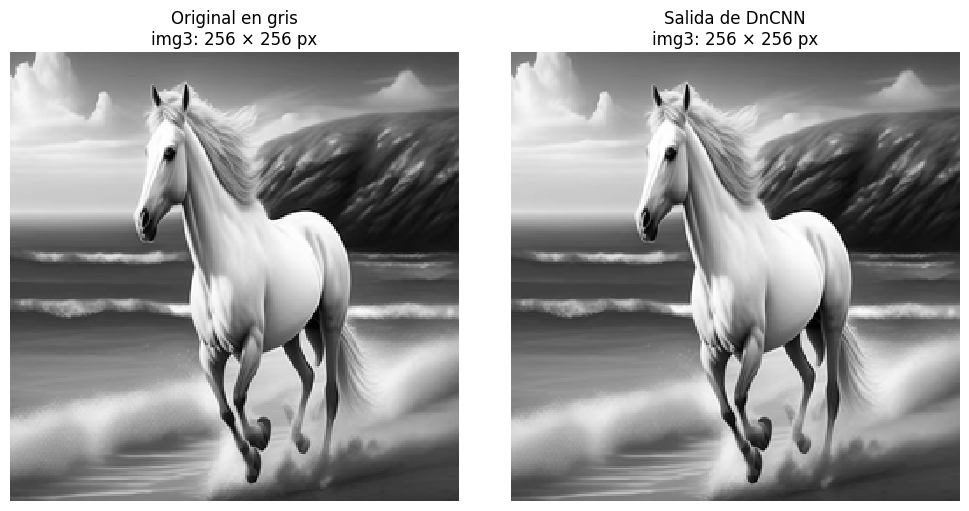

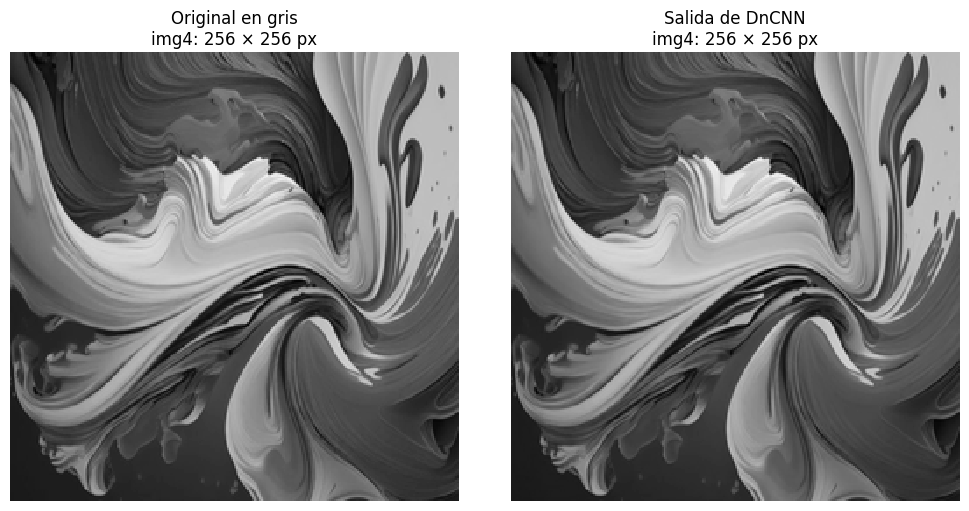

,Imagen,Entrada (ancho × alto),Salida (ancho × alto),Dimensiones conservadas,Valores finitos
0,img1,256 × 256,256 × 256,True,True
1,img2,256 × 256,256 × 256,True,True
2,img3,256 × 256,256 × 256,True,True
3,img4,256 × 256,256 × 256,True,True


4a completado: 4 imágenes procesadas sin entrenamiento.
Inciso 4a: PNG individuales y comparativos guardados en: C:\Users\mclai\Documents\GALILEO\6SEMESTRE\Matematica\final_proj_mate_6\reporte\figuras\cnn\4a


In [58]:
#inciso 4a: cargar DnCNN y aplicarla a las imágenes ya preparadas
from pathlib import Path
import hashlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
import torch
import torch.nn as nn

#CARPETA_IMAGENES ya apunta a ../imagenes desde la carpeta notebooks
RAIZ = CARPETA_IMAGENES.resolve().parent
#ruta local de los pesos preentrenados y direccion de descarga
RUTA_PESOS = RAIZ / "herramientas" / "model_zoo" / "dncnn_gray_blind.pth"
URL_PESOS = "https://github.com/cszn/KAIR/releases/download/v1.0/dncnn_gray_blind.pth"
#si los pesos no existen se descargan una sola vez
if not RUTA_PESOS.is_file():
    #se crea la carpeta donde se guardan los pesos
    RUTA_PESOS.parent.mkdir(parents=True, exist_ok=True)
    print("Descargando los pesos preentrenados de DnCNN...")
    #intento de descarga de los pesos oficiales
    try:
        torch.hub.download_url_to_file(URL_PESOS, str(RUTA_PESOS), progress=True)
    #si la descarga falla se indica como guardar los pesos manualmente
    except Exception as error:
        raise RuntimeError(
            f"No se pudieron descargar los pesos. Descarga {URL_PESOS} "
            f"y guarda el archivo en {RUTA_PESOS}."
        ) from error

#equivalente a KAIR: DnCNN(in_nc=1, out_nc=1, nc=64, nb=20, act_mode='R')
class DnCNNGrayKAIR(nn.Module):
    #funcion que define las capas de la red
    def __init__(self):
        #inicializacion de la clase base de PyTorch
        super().__init__()
        #primera capa convolucional y activacion ReLU
        capas = [nn.Conv2d(1, 64, 3, padding=1), nn.ReLU(inplace=True)]
        #capas intermedias que extraen caracteristicas de la imagen
        for _ in range(18):
            capas.extend([nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(inplace=True)])
        #ultima capa que estima el ruido en un solo canal
        capas.append(nn.Conv2d(64, 1, 3, padding=1))
        #las capas se unen para ejecutarse en orden
        self.model = nn.Sequential(*capas)

    #funcion que resta el ruido estimado de la imagen de entrada
    def forward(self, x):
        return x - self.model(x)

#se usa la GPU si esta disponible o el procesador en caso contrario
dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
#creacion de la red y carga de los pesos preentrenados
modelo_dncnn_4a = DnCNNGrayKAIR()
estado = torch.load(RUTA_PESOS, map_location="cpu", weights_only=True)
modelo_dncnn_4a.load_state_dict(estado, strict=True)
#se mueve la red al dispositivo y se activa el modo de evaluacion
modelo_dncnn_4a = modelo_dncnn_4a.to(dispositivo).eval()
#se desactiva el calculo de gradientes porque no se entrena la red
modelo_dncnn_4a.requires_grad_(False)

#funcion que aplica la CNN a una imagen en gris
def aplicar_cnn(img):
    """Procesar una imagen gris 2D en [0, 1], conservando su tamaño."""
    #conversion de los pixeles a decimales de 32 bits
    entrada = np.asarray(img, dtype=np.float32)
    #se verifica que la imagen sea una matriz de dos dimensiones no vacia
    if entrada.ndim != 2 or entrada.size == 0:
        raise ValueError("Se requiere una imagen en gris con forma (alto, ancho).")
    #se comprueba que los valores sean finitos y esten entre 0 y 1
    if not np.isfinite(entrada).all() or entrada.min() < 0 or entrada.max() > 1:
        raise ValueError("La imagen debe contener valores finitos en [0, 1].")
    #se agregan los ejes de lote y canal que espera PyTorch
    tensor = torch.from_numpy(entrada.copy())[None, None].to(dispositivo)
    #se procesa la imagen sin calcular gradientes
    with torch.inference_mode():
        prediccion = modelo_dncnn_4a(tensor)
    #se comprueba que la salida conserve el tamano y tenga valores validos
    if prediccion.shape != tensor.shape or not torch.isfinite(prediccion).all().item():
        raise RuntimeError("DnCNN produjo dimensiones o valores inválidos.")
    #se limita la salida a [0, 1] y se devuelve como arreglo de NumPy
    return prediccion.clamp(0, 1)[0, 0].cpu().numpy()

#se muestran el modelo, el dispositivo y la huella de los pesos utilizados
print(f"Modelo: dncnn_gray_blind (KAIR v1.0) | PyTorch: {torch.__version__}")
print(f"Dispositivo: {dispositivo} | Pesos: {RUTA_PESOS}")
print(f"SHA-256: {hashlib.sha256(RUTA_PESOS.read_bytes()).hexdigest()}")

#diccionario de salidas y lista de comprobaciones por imagen
resultados_dncnn_4a = {}
registros = []
#recorrido de las imagenes cargadas para aplicar la CNN
for nombre, entrada in imagenes.items():
    #se procesa la imagen y se conserva el resultado
    salida = aplicar_cnn(entrada)
    resultados_dncnn_4a[nombre] = salida
    #guardado de la entrada y la salida como PNG individuales
    plt.imsave(CARPETA_CNN / "4a" / f"4a_{nombre}_original.png", entrada, cmap="gray", vmin=0, vmax=1)
    plt.imsave(CARPETA_CNN / "4a" / f"4a_{nombre}_dncnn.png", salida, cmap="gray", vmin=0, vmax=1)
    #dimensiones de la imagen para identificar la comparacion
    alto, ancho = entrada.shape
    #figura con la imagen original y la salida de la CNN
    fig, ejes = plt.subplots(1, 2, figsize=(10, 5), constrained_layout=True)
    #se muestra cada imagen con la misma escala de grises
    for ax, imagen, titulo in zip(
        ejes, (entrada, salida), ("Original en gris", "Salida de DnCNN")
    ):
        ax.imshow(imagen, cmap="gray", vmin=0, vmax=1, interpolation="nearest")
        ax.set_title(f"{titulo}\n{nombre}: {ancho} × {alto} px")
        ax.axis("off")
    #guardado de la figura comparativa en la carpeta del inciso
    fig.savefig(CARPETA_CNN / "4a" / f"4a_{nombre}_dncnn_comparacion.png", dpi=150, bbox_inches="tight")
    #se muestra la figura y se cierra para liberar memoria
    plt.show()
    plt.close(fig)
    #registro de dimensiones y validez de los resultados
    registros.append({
        "Imagen": nombre,
        "Entrada (ancho × alto)": f"{ancho} × {alto}",
        "Salida (ancho × alto)": f"{salida.shape[1]} × {salida.shape[0]}",
        "Dimensiones conservadas": entrada.shape == salida.shape,
        "Valores finitos": bool(np.isfinite(salida).all()),
    })

#tabla con las comprobaciones de todas las imagenes
tabla_4a = pd.DataFrame(registros)
#se muestran la tabla y los mensajes de finalizacion y guardado
display(tabla_4a)
print(f"4a completado: {len(resultados_dncnn_4a)} imágenes procesadas sin entrenamiento.")
print(f"Inciso 4a: PNG individuales y comparativos guardados en: {(CARPETA_CNN / '4a').resolve()}")


## Inciso 4b. Ruido artificial

Tome una de las imágenes originales y agréguele ruido artificialmente (puede usar la
biblioteca `scikit-image' o `OpenCV').


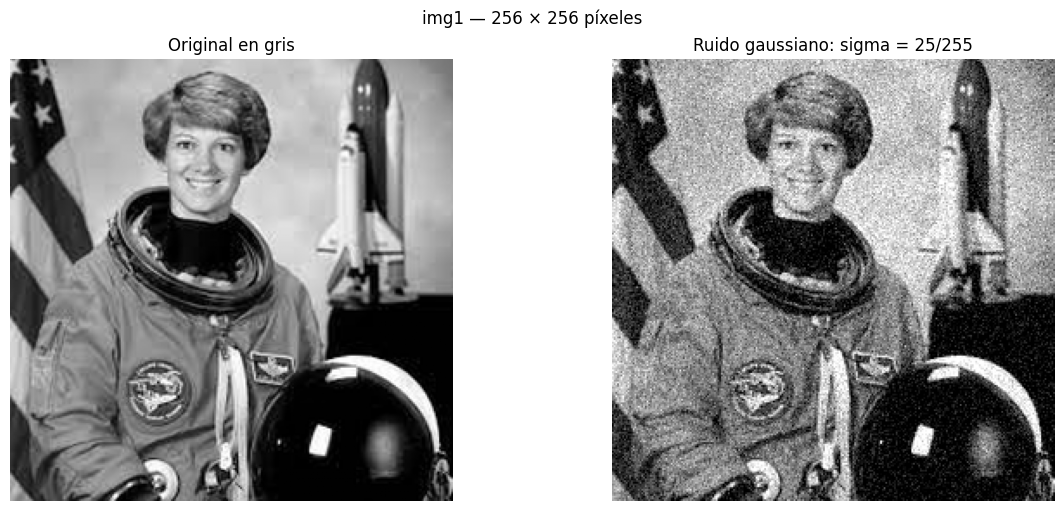

img1: referencia y ruido guardados, tamaño 256 × 256.


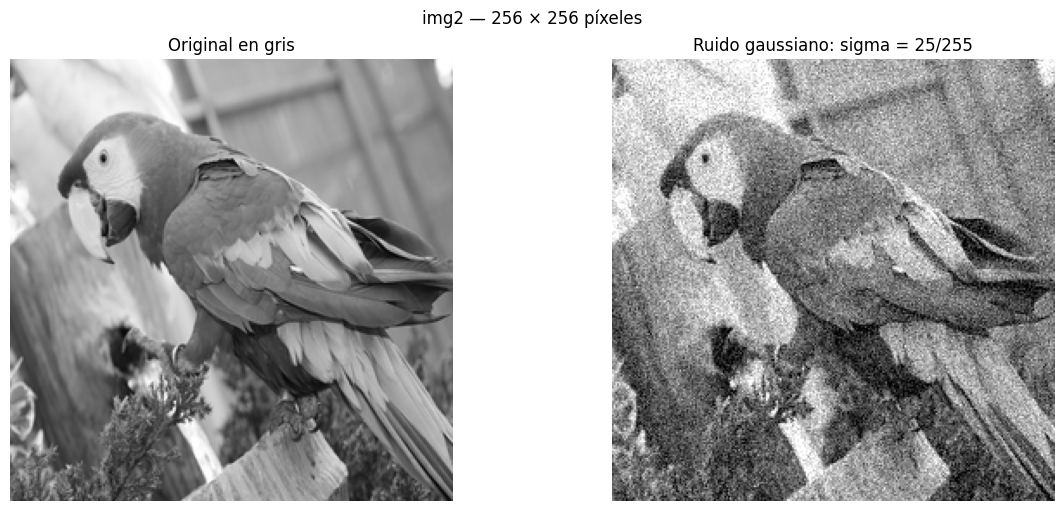

img2: referencia y ruido guardados, tamaño 256 × 256.


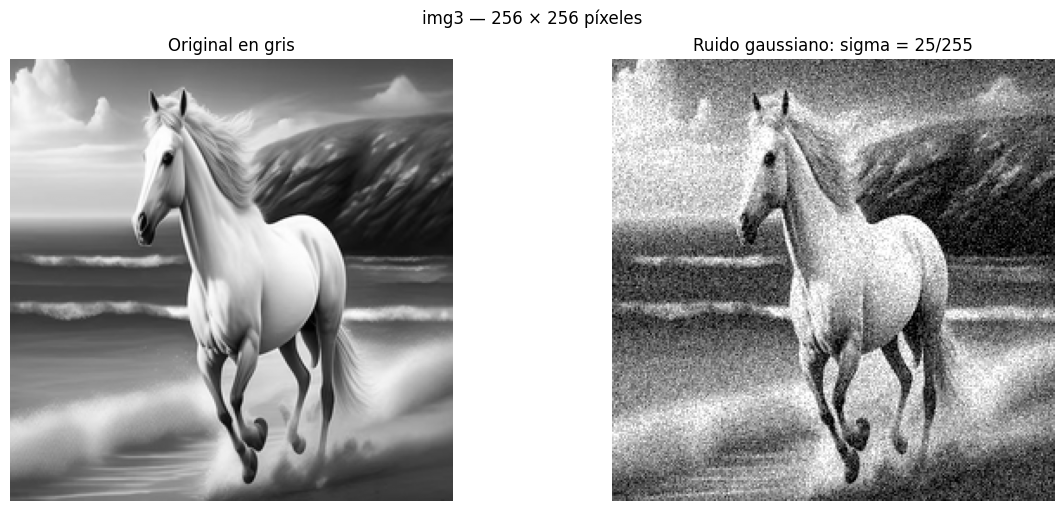

img3: referencia y ruido guardados, tamaño 256 × 256.


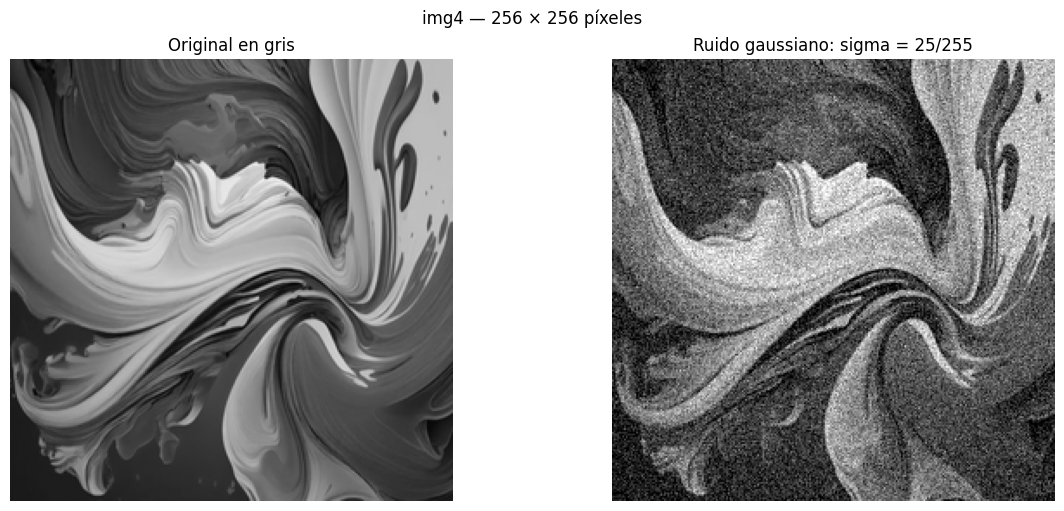

img4: referencia y ruido guardados, tamaño 256 × 256.
4b completado: 4 imágenes con ruido reproducible.
Arreglos para FFT y DnCNN: C:\Users\mclai\Documents\GALILEO\6SEMESTRE\Matematica\final_proj_mate_6\resultados\ruido_gaussiano
Inciso 4b: PNG individuales y comparativos guardados en: C:\Users\mclai\Documents\GALILEO\6SEMESTRE\Matematica\final_proj_mate_6\reporte\figuras\cnn\4b


In [59]:
#inciso 4b: preparar las imágenes con ruido usando la carga del notebook
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

#ruta del proyecto y carpeta para conservar los arreglos con ruido
RAIZ = CARPETA_IMAGENES.resolve().parent
CARPETA_RUIDO = RAIZ / "resultados" / "ruido_gaussiano"
#se crean las carpetas de salida si no existen
CARPETA_RUIDO.mkdir(parents=True, exist_ok=True)
(CARPETA_CNN / "4b").mkdir(parents=True, exist_ok=True)
#intensidad del ruido y semilla para repetir el experimento
SIGMA = 25 / 255
SEMILLA = 42

#copias independientes: las imágenes originales del notebook se conservan
originales_4b = {}
imagenes_ruido = {}

#recorrido de las imagenes originales
for nombre, imagen in imagenes.items():
    #copia de la imagen en decimales de 32 bits
    original = np.array(imagen, dtype=np.float32, copy=True)
    #se comprueba que la imagen sea una matriz no vacia
    if original.ndim != 2 or original.size == 0:
        raise ValueError(f"{nombre}: se esperaba una imagen en gris de dos dimensiones.")
    #se verifican los valores finitos y el rango [0, 1]
    if not np.isfinite(original).all() or original.min() < 0 or original.max() > 1:
        raise ValueError(f"{nombre}: la imagen debe contener valores finitos en [0, 1].")

    #reiniciar la semilla por imagen conserva el criterio del experimento previo
    rng = np.random.default_rng(SEMILLA)
    #ruido gaussiano de media cero con el mismo tamano que la imagen
    ruido = rng.normal(0, SIGMA, original.shape).astype(np.float32)
    #se suma el ruido y se limita la imagen al rango [0, 1]
    imagen_ruidosa = np.clip(original + ruido, 0, 1)
    #se comprueba que el ruido no cambie las dimensiones ni produzca valores invalidos
    assert original.shape == imagen_ruidosa.shape
    assert np.isfinite(imagen_ruidosa).all()

    #se conservan las mismas referencias y entradas para FFT y CNN
    originales_4b[nombre] = original
    imagenes_ruido[nombre] = imagen_ruidosa
    #guardado de los arreglos originales y ruidosos para los siguientes incisos
    np.save(CARPETA_RUIDO / f"{nombre}_gris.npy", original)
    np.save(CARPETA_RUIDO / f"{nombre}_ruido_gaussiano.npy", imagen_ruidosa)
    #guardado de las imagenes individuales en la carpeta del inciso
    plt.imsave(CARPETA_CNN / "4b" / f"4b_{nombre}_original.png", original, cmap="gray", vmin=0, vmax=1)
    plt.imsave(CARPETA_CNN / "4b" / f"4b_{nombre}_ruido_gaussiano.png", imagen_ruidosa, cmap="gray", vmin=0, vmax=1)

    #dimensiones de la imagen para el titulo de la figura
    alto, ancho = original.shape
    #figura que compara la imagen original con la imagen ruidosa
    fig, ejes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
    #se muestran ambas imagenes con la misma escala de intensidades
    for eje, datos, titulo in zip(
        ejes, (original, imagen_ruidosa),
        ("Original en gris", "Ruido gaussiano: sigma = 25/255")
    ):
        eje.imshow(datos, cmap="gray", vmin=0, vmax=1, aspect="equal")
        eje.set_title(titulo)
        eje.axis("off")
    #titulo y guardado de la figura comparativa
    fig.suptitle(f"{nombre} — {ancho} × {alto} píxeles")
    fig.savefig(CARPETA_CNN / "4b" / f"4b_{nombre}_ruido_gaussiano_comparacion.png",
                dpi=150, bbox_inches="tight")
    #se muestra la figura y se cierra para liberar memoria
    plt.show()
    plt.close(fig)
    #mensaje de procesamiento de la imagen actual
    print(f"{nombre}: referencia y ruido guardados, tamaño {ancho} × {alto}.")

#resumen del inciso y ubicacion de los archivos guardados
print(f"4b completado: {len(imagenes_ruido)} imágenes con ruido reproducible.")
print(f"Arreglos para FFT y DnCNN: {CARPETA_RUIDO}")
print(f"Inciso 4b: PNG individuales y comparativos guardados en: {(CARPETA_CNN / '4b').resolve()}")


## Inciso 4c. Limpieza con los filtros de FFT
Aplique los filtros de FFT implementados para intentar limpiar la imagen.


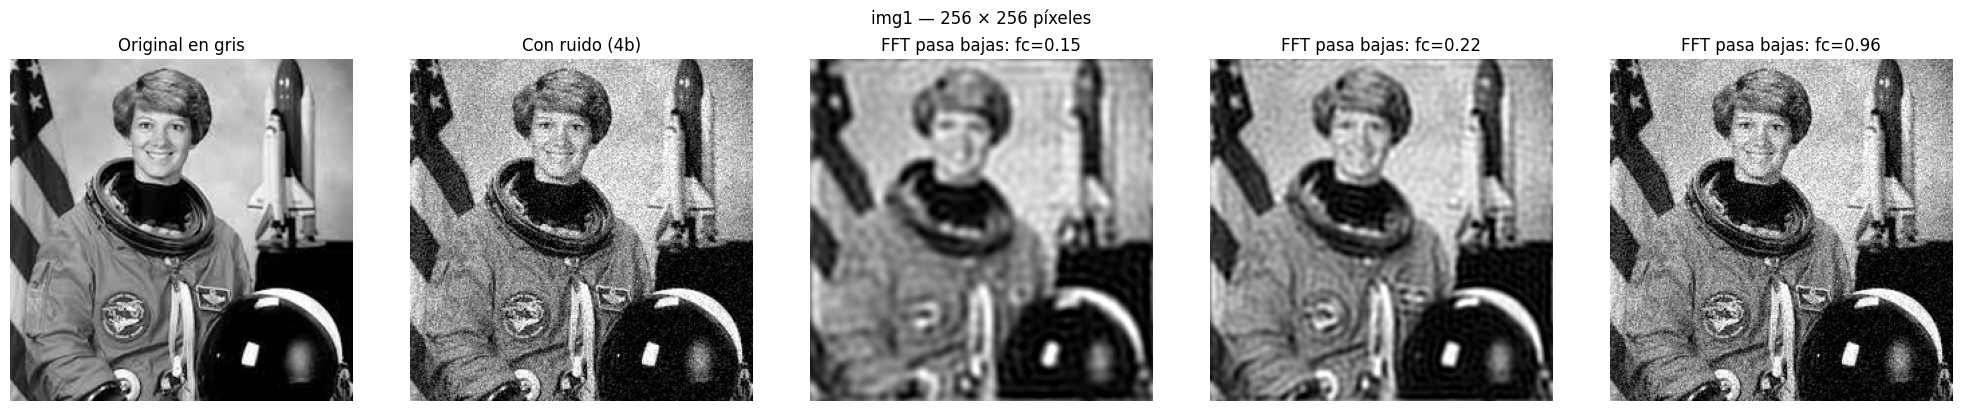

img1: filtros aplicados sin generar ruido nuevo ni redimensionar.


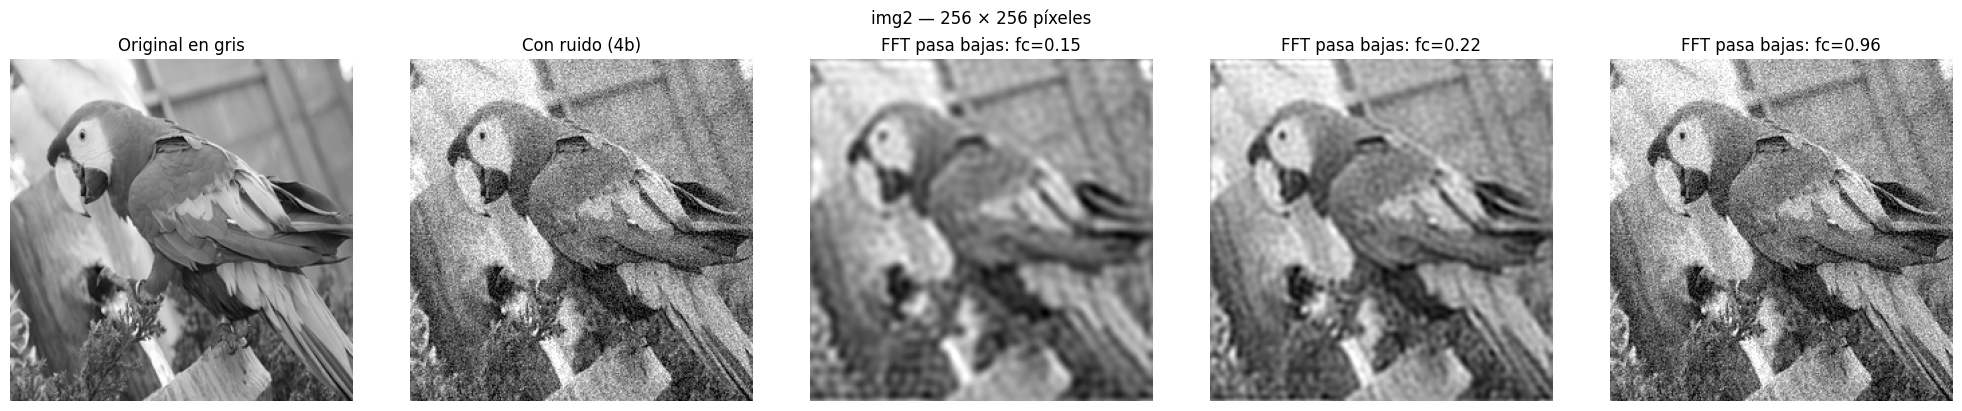

img2: filtros aplicados sin generar ruido nuevo ni redimensionar.


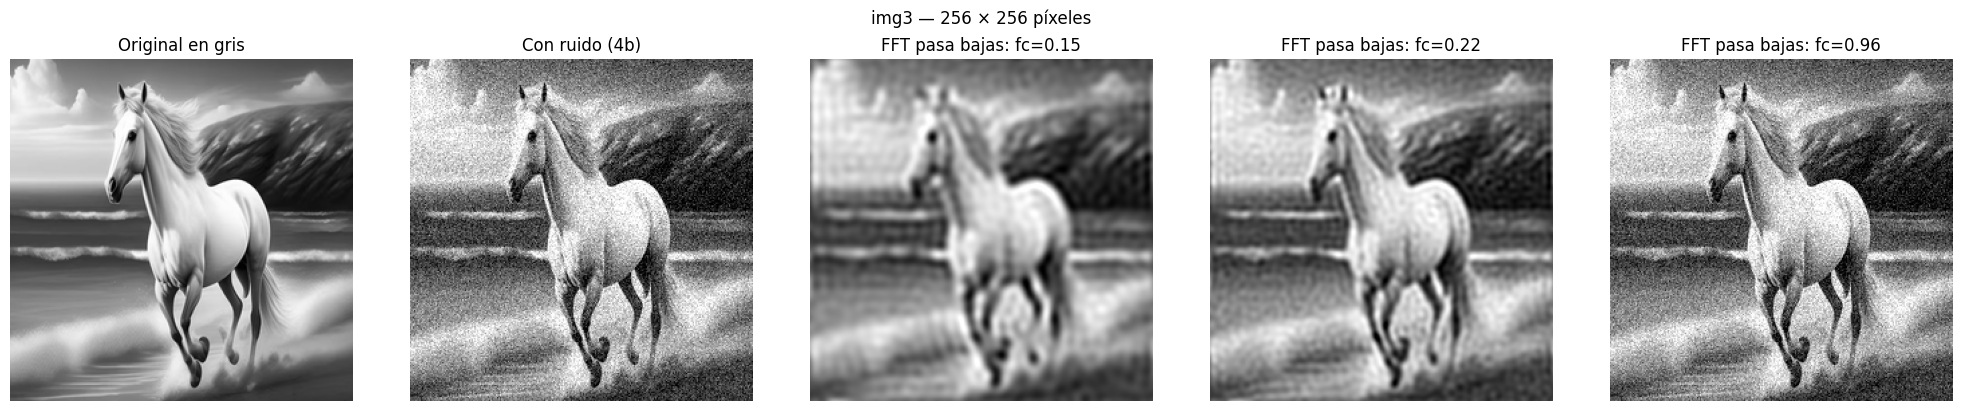

img3: filtros aplicados sin generar ruido nuevo ni redimensionar.


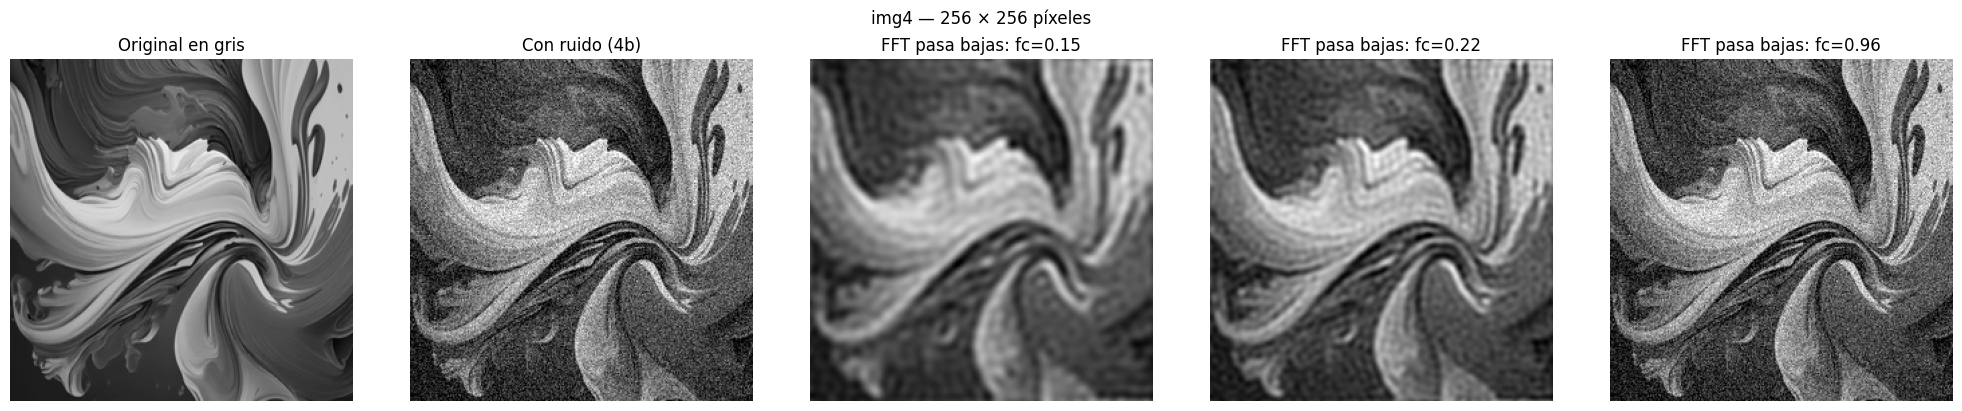

img4: filtros aplicados sin generar ruido nuevo ni redimensionar.
Resultados FFT guardados en: C:\Users\mclai\Documents\GALILEO\6SEMESTRE\Matematica\final_proj_mate_6\resultados\fft
Inciso 4c: PNG individuales y comparativos guardados en: C:\Users\mclai\Documents\GALILEO\6SEMESTRE\Matematica\final_proj_mate_6\reporte\figuras\cnn\4c


In [60]:
#tODO: limpiar img_ruido con filtro_pasabajas y varios fc
#inciso 4c: limpiar las entradas de 4b con la FFT de Tony
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

#ruta del proyecto para importar el nucleo de FFT
RAIZ = CARPETA_IMAGENES.resolve().parent
#se agrega la carpeta del nucleo si todavia no esta en las rutas de importacion
if str(RAIZ / "src") not in sys.path:
    sys.path.insert(0, str(RAIZ / "src"))

#funciones de filtrado y comprobacion de dimensiones del nucleo
from fft_nucleo import filtro_pasabajas, es_potencia_de_2

#carpetas de entrada y salida de los resultados FFT
CARPETA_RUIDO = RAIZ / "resultados" / "ruido_gaussiano"
CARPETA_FFT = RAIZ / "resultados" / "fft"
#frecuencias de corte que se prueban con el filtro pasa bajas
FC_4C = (0.15, 0.22, 0.96)

#se comprueba que la carga de imagenes ya se haya ejecutado
if "imagenes" not in globals() or not imagenes:
    raise RuntimeError("Ejecuta primero la sección de carga de imágenes.")

#comprobar que estén todas las entradas guardadas en 4b
for nombre in imagenes:
    #se buscan tanto la referencia como la entrada ruidosa de cada imagen
    for sufijo in ("gris", "ruido_gaussiano"):
        ruta = CARPETA_RUIDO / f"{nombre}_{sufijo}.npy"
        #si falta una entrada se solicita ejecutar el inciso 4b
        if not ruta.is_file():
            raise FileNotFoundError(f"Falta {ruta}. Ejecuta primero 4b.")

#se crean las carpetas de salida si no existen
CARPETA_FFT.mkdir(parents=True, exist_ok=True)
(CARPETA_CNN / "4c").mkdir(parents=True, exist_ok=True)
#diccionario para conservar los resultados de cada frecuencia de corte
resultados_fft_4c = {}

#recorrido de las imagenes del proyecto
for nombre in imagenes:
    #carga de la referencia y de la imagen con el ruido guardado en 4b
    original = np.load(
        CARPETA_RUIDO / f"{nombre}_gris.npy",
        allow_pickle=False
    )
    ruidosa = np.load(
        CARPETA_RUIDO / f"{nombre}_ruido_gaussiano.npy",
        allow_pickle=False
    )

    #se comprueba que ambas entradas sean matrices del mismo tamano
    if original.ndim != 2 or original.shape != ruidosa.shape:
        raise ValueError(
            f"{nombre}: las entradas deben ser imágenes 2D del mismo tamaño."
        )
    #la FFT recursiva requiere dimensiones que sean potencias de 2
    if not all(es_potencia_de_2(n) for n in ruidosa.shape):
        raise ValueError(
            f"{nombre}: la FFT requiere dimensiones potencia de 2. Repite 4b."
        )
    #se verifican los valores finitos y el rango [0, 1] de las entradas
    for datos in (original, ruidosa):
        if not np.isfinite(datos).all() or datos.min() < 0 or datos.max() > 1:
            raise ValueError(f"{nombre}: se requieren valores finitos en [0, 1].")

    #se preparan las salidas y los paneles de comparacion de esta imagen
    resultados_fft_4c[nombre] = {}
    paneles = [original, ruidosa]
    titulos = ["Original en gris", "Con ruido (4b)"]
    #guardado de la referencia y la entrada ruidosa como PNG individuales
    plt.imsave(CARPETA_CNN / "4c" / f"4c_{nombre}_original.png", original, cmap="gray", vmin=0, vmax=1)
    plt.imsave(CARPETA_CNN / "4c" / f"4c_{nombre}_ruido_gaussiano.png", ruidosa, cmap="gray", vmin=0, vmax=1)

    #se aplica el filtro a la misma entrada con cada frecuencia de corte
    for fc in FC_4C:
        #usa la FFT propia de Tony y limita la salida a [0, 1]
        resultado = filtro_pasabajas(ruidosa, fc, tipo="ideal")

        #se verifica que el filtro conserve el tamano y produzca valores finitos
        if resultado.shape != original.shape or not np.isfinite(resultado).all():
            raise RuntimeError(f"Salida inválida para {nombre}, fc={fc}.")

        #se conserva la salida y se guarda el PNG de cada corte
        resultados_fft_4c[nombre][fc] = resultado
        plt.imsave(CARPETA_CNN / "4c" / f"4c_{nombre}_fft_fc_{fc:.2f}.png", resultado, cmap="gray", vmin=0, vmax=1)
        #guardado del arreglo numerico para calcular las metricas del inciso 5
        np.save(
            CARPETA_FFT / f"{nombre}_restaurada_fft_fc_{fc:.2f}.npy",
            resultado
        )
        #se agrega la salida y su titulo a la comparacion
        paneles.append(resultado)
        titulos.append(f"FFT pasa bajas: fc={fc}")

    #figura con la referencia, la entrada ruidosa y los tres resultados FFT
    fig, ejes = plt.subplots(
        1, len(paneles), figsize=(20, 4), constrained_layout=True
    )
    #se muestra cada panel con la misma escala de grises
    for eje, datos, titulo in zip(ejes, paneles, titulos):
        eje.imshow(datos, cmap="gray", vmin=0, vmax=1, aspect="equal")
        eje.set_title(titulo)
        eje.axis("off")

    #dimensiones de la imagen para el titulo de la figura
    alto, ancho = original.shape
    fig.suptitle(f"{nombre} — {ancho} × {alto} píxeles")
    #guardado de la figura comparativa en la carpeta del inciso
    fig.savefig(
        CARPETA_CNN / "4c" / f"4c_{nombre}_fft_comparacion.png",
        dpi=150, bbox_inches="tight"
    )
    #se muestra la figura y se cierra para liberar memoria
    plt.show()
    plt.close(fig)

    #mensaje de procesamiento de la imagen actual
    print(f"{nombre}: filtros aplicados sin generar ruido nuevo ni redimensionar.")

#ubicacion de los arreglos y de las imagenes PNG guardadas
print(f"Resultados FFT guardados en: {CARPETA_FFT}")
print(f"Inciso 4c: PNG individuales y comparativos guardados en: {(CARPETA_CNN / '4c').resolve()}")


## Inciso 4d. Limpieza con la CNN

Aplique el filtro basado en IA a la misma imagen con ruido.


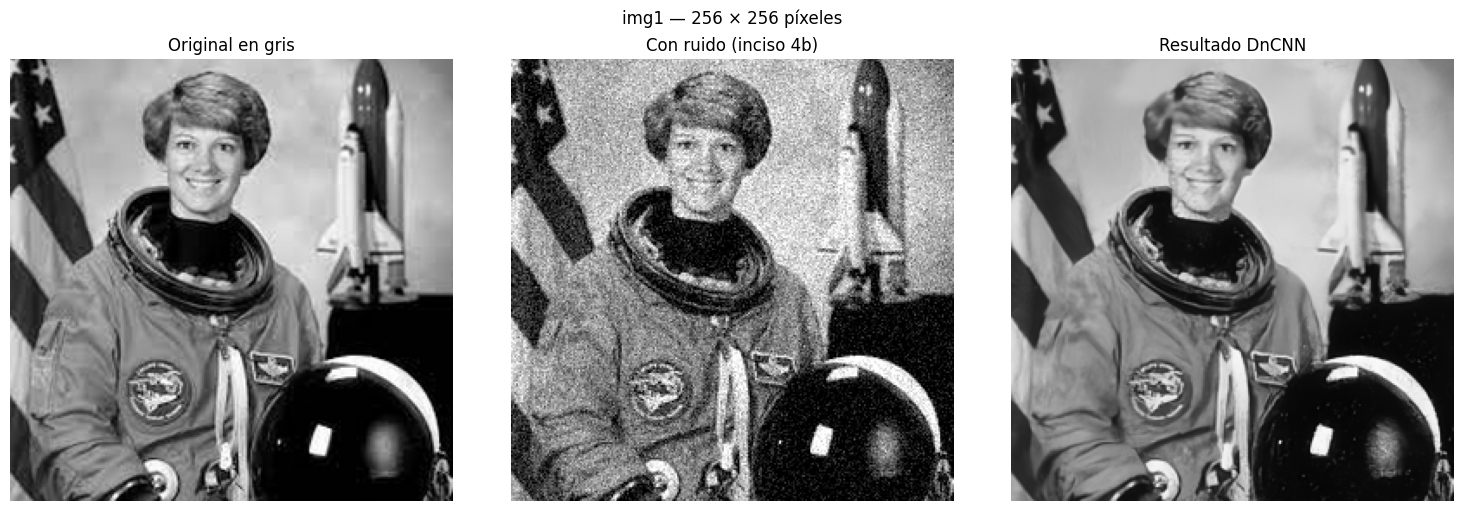

img1: DnCNN aplicada sin generar ruido nuevo ni redimensionar.


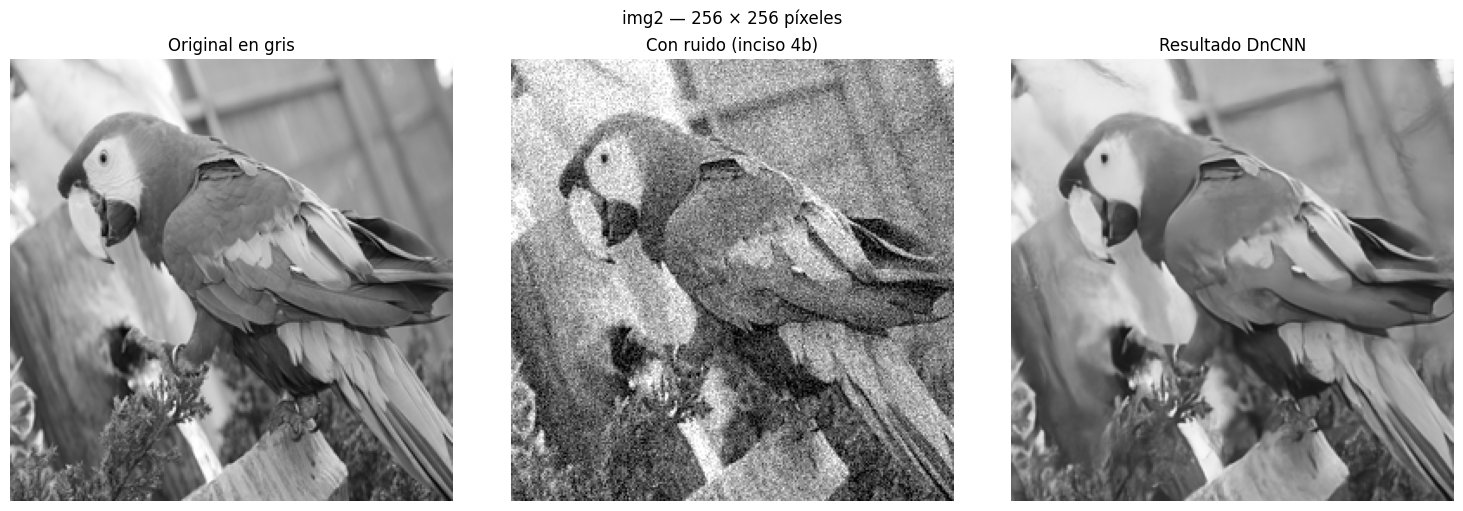

img2: DnCNN aplicada sin generar ruido nuevo ni redimensionar.


In [ ]:
#inciso 4d: aplicar el modelo de 4a a las entradas guardadas en 4b
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import torch

#se comprueba que el modelo de 4a ya este cargado
if "modelo_dncnn_4a" not in globals():
    raise RuntimeError("Ejecuta primero el inciso 4a para cargar DnCNN.")
#se comprueba que la carga de imagenes ya se haya ejecutado
if "imagenes" not in globals() or not imagenes:
    raise RuntimeError("Ejecuta primero la sección de carga de imágenes.")

#rutas del proyecto y de los arreglos de entrada y salida
RAIZ = CARPETA_IMAGENES.resolve().parent
CARPETA_RUIDO = RAIZ / "resultados" / "ruido_gaussiano"
CARPETA_DNCNN = RAIZ / "resultados" / "dncnn"
#nombres de las mismas imagenes utilizadas en el inciso 4b
NOMBRES = tuple(imagenes)  #img1, img2, img3, img4: mismas claves que en 4b

#comprobar que todas las entradas existen antes de comenzar la inferencia
for nombre in NOMBRES:
    #se verifica que existan la referencia y la entrada ruidosa de cada imagen
    for sufijo in ("gris", "ruido_gaussiano"):
        ruta = CARPETA_RUIDO / f"{nombre}_{sufijo}.npy"
        #si falta una entrada se solicita ejecutar el inciso 4b
        if not ruta.is_file():
            raise FileNotFoundError(f"Falta {ruta}. Ejecuta primero el inciso 4b.")

#se crean las carpetas de salida si no existen
CARPETA_DNCNN.mkdir(parents=True, exist_ok=True)
(CARPETA_CNN / "4d").mkdir(parents=True, exist_ok=True)
#se activa el modo de evaluacion del modelo preentrenado
modelo_dncnn_4a.eval()
#se utiliza el mismo dispositivo donde estan los pesos de la red
dispositivo = next(modelo_dncnn_4a.parameters()).device
#listas y diccionarios para conservar las comprobaciones y las salidas
registros_4d = []
resultados_dncnn_4d = {}
resultados_crudos_dncnn_4d = {}

#recorrido de las mismas entradas guardadas en 4b
for nombre in NOMBRES:
    #rutas de la referencia y de la imagen ruidosa
    ruta_original = CARPETA_RUIDO / f"{nombre}_gris.npy"
    ruta_ruidosa = CARPETA_RUIDO / f"{nombre}_ruido_gaussiano.npy"
    #carga de los arreglos sin generar ruido nuevo
    original = np.load(ruta_original, allow_pickle=False)
    imagen_ruidosa = np.load(ruta_ruidosa, allow_pickle=False)
    #se comprueba que ambas imagenes sean matrices no vacias
    if original.ndim != 2 or imagen_ruidosa.ndim != 2 or original.size == 0:
        raise ValueError(f"{nombre}: las entradas deben ser imágenes en gris no vacías.")
    #se comprueba que las dimensiones de ambas entradas coincidan
    if original.shape != imagen_ruidosa.shape:
        raise ValueError(f"{nombre}: las dimensiones de las entradas de 4b no coinciden.")
    #se verifican los valores finitos y el rango [0, 1]
    for datos in (original, imagen_ruidosa):
        if not np.isfinite(datos).all() or datos.min() < 0 or datos.max() > 1:
            raise ValueError(f"{nombre}: se requieren valores finitos en [0, 1].")

    #conversion de la imagen ruidosa a un tensor de PyTorch
    entrada = torch.from_numpy(np.ascontiguousarray(imagen_ruidosa, dtype=np.float32))
    #se agregan los ejes de lote y canal y se envia al dispositivo
    entrada = entrada[None, None].to(dispositivo)
    #se aplica la red sin entrenamiento ni calculo de gradientes
    with torch.inference_mode():
        salida = modelo_dncnn_4a(entrada)
    #se comprueba que la salida tenga el mismo tamano y valores finitos
    if salida.shape != entrada.shape or not torch.isfinite(salida).all().item():
        raise RuntimeError(f"{nombre}: DnCNN produjo dimensiones o valores inválidos.")

    #se usa el modelo directamente para conservar también la salida sin recorte
    salida_cruda = salida[0, 0].cpu().numpy()
    #se limita la salida restaurada al rango valido [0, 1]
    resultado = np.clip(salida_cruda, 0, 1)
    #guardado de la salida cruda y la salida restaurada como arreglos
    np.save(CARPETA_DNCNN / f"{nombre}_salida_cruda_dncnn.npy", salida_cruda)
    np.save(CARPETA_DNCNN / f"{nombre}_restaurada_dncnn.npy", resultado)
    #se conservan ambas salidas para la comparacion posterior
    resultados_crudos_dncnn_4d[nombre] = salida_cruda
    resultados_dncnn_4d[nombre] = resultado
    #guardado de la referencia, la entrada ruidosa y el resultado como PNG individuales
    plt.imsave(CARPETA_CNN / "4d" / f"4d_{nombre}_original.png", original, cmap="gray", vmin=0, vmax=1)
    plt.imsave(CARPETA_CNN / "4d" / f"4d_{nombre}_ruido_gaussiano.png", imagen_ruidosa, cmap="gray", vmin=0, vmax=1)
    plt.imsave(CARPETA_CNN / "4d" / f"4d_{nombre}_dncnn.png", resultado, cmap="gray", vmin=0, vmax=1)

    #dimensiones de la imagen para preparar la comparacion
    alto, ancho = original.shape
    #figura con la referencia, la imagen ruidosa y la salida de DnCNN
    fig, ejes = plt.subplots(1, 3, figsize=(15, 5), constrained_layout=True)
    #se muestran los tres paneles con la misma escala de grises
    for eje, datos, titulo in zip(
        ejes, (original, imagen_ruidosa, resultado),
        ("Original en gris", "Con ruido (inciso 4b)", "Resultado DnCNN")
    ):
        eje.imshow(datos, cmap="gray", vmin=0, vmax=1, aspect="equal")
        eje.set_title(titulo)
        eje.axis("off")
    #titulo y guardado de la figura comparativa
    fig.suptitle(f"{nombre} — {ancho} × {alto} píxeles")
    fig.savefig(CARPETA_CNN / "4d" / f"4d_{nombre}_dncnn_comparacion.png", dpi=150, bbox_inches="tight")
    #se muestra la figura y se cierra para liberar memoria
    plt.show()
    plt.close(fig)
    #registro del tamano de la salida y del archivo de entrada utilizado
    registros_4d.append({
        "Imagen": nombre, "Ancho": ancho, "Alto": alto,
        "Dimensiones conservadas": resultado.shape == original.shape,
        "Entrada": ruta_ruidosa.name,
    })
    #mensaje de procesamiento de la imagen actual
    print(f"{nombre}: DnCNN aplicada sin generar ruido nuevo ni redimensionar.")

#tabla con las comprobaciones de todas las imagenes procesadas
tabla_4d = pd.DataFrame(registros_4d)
#se muestra el resumen de procesamiento
display(tabla_4d)
#guardado de la tabla y mensajes con la ubicacion de los resultados
tabla_4d.to_csv(CARPETA_DNCNN / "resumen_4d.csv", index=False)
print(f"4d completado: {len(resultados_dncnn_4d)} imágenes. Resultados: {CARPETA_DNCNN}")
print(f"Inciso 4d: PNG individuales y comparativos guardados en: {(CARPETA_CNN / '4d').resolve()}")


## Inciso 5. Comparación con MSE, PSNR y SSIM

¿Cuál filtro funcionó mejor? Justifique su respuesta mostrando las imágenes resultantes y
explicando brevemente cómo la IA puede superar a los filtros clásicos en ciertas tareas al
"aprender" las características de una imagen limpia.


In [ ]:
#inciso 5: comparar las salidas de 4c y 4d contra las referencias de 4b
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
#si falta esta librería, ejecutar en otra celda: %pip install scikit-image
from skimage.metrics import mean_squared_error, peak_signal_noise_ratio, structural_similarity

#se comprueba que la carga de imagenes ya se haya ejecutado
if "imagenes" not in globals() or not imagenes:
    raise RuntimeError("Ejecuta primero la sección de carga de imágenes.")

#rutas de las referencias, los resultados y las tablas de comparacion
RAIZ = CARPETA_IMAGENES.resolve().parent
CARPETA_RUIDO = RAIZ / "resultados" / "ruido_gaussiano"
CARPETA_FFT = RAIZ / "resultados" / "fft"
CARPETA_DNCNN = RAIZ / "resultados" / "dncnn"
CARPETA_COMPARACION = RAIZ / "resultados" / "comparacion"
#frecuencias de corte que se evaluaron en el inciso 4c
FC_5 = (0.15, 0.22, 0.96)  #los tres filtros pasa bajas del inciso 4c

#comprobar los archivos antes de generar resultados parciales
for nombre in imagenes:
    #lista de entradas necesarias para comparar todos los metodos
    requeridos = [
        (CARPETA_RUIDO / f"{nombre}_gris.npy", "4b"),
        (CARPETA_RUIDO / f"{nombre}_ruido_gaussiano.npy", "4b"),
        (CARPETA_DNCNN / f"{nombre}_restaurada_dncnn.npy", "4d"),
        *[(CARPETA_FFT / f"{nombre}_restaurada_fft_fc_{fc:.2f}.npy", "4c")
          for fc in FC_5],
    ]
    #se verifica que cada archivo exista antes de iniciar la comparacion
    for ruta, inciso in requeridos:
        if not ruta.is_file():
            raise FileNotFoundError(f"Falta {ruta}. Ejecuta primero el inciso {inciso}.")

#se crean las carpetas para las tablas y las imagenes del inciso
CARPETA_COMPARACION.mkdir(parents=True, exist_ok=True)
(CARPETA_CNN / "5").mkdir(parents=True, exist_ok=True)

#funcion que calcula las metricas de cada resultado frente a la referencia
def medir_error(referencia, resultado):
    """MSE, PSNR y SSIM para imágenes en gris normalizadas a [0, 1]."""
    #conversion a decimales de 64 bits para calcular las metricas
    referencia = np.asarray(referencia, dtype=np.float64)
    resultado = np.asarray(resultado, dtype=np.float64)
    #se comprueba que las imagenes sean matrices del mismo tamano
    if referencia.ndim != 2 or referencia.shape != resultado.shape:
        raise ValueError("La referencia y el resultado deben ser imágenes 2D del mismo tamaño.")
    #SSIM necesita al menos 7 pixeles por dimension con esta configuracion
    if min(referencia.shape) < 7:
        raise ValueError("SSIM requiere al menos 7 píxeles por dimensión en esta configuración.")
    #se verifican los valores finitos y el rango [0, 1]
    for datos in (referencia, resultado):
        if not np.isfinite(datos).all() or datos.min() < 0 or datos.max() > 1:
            raise ValueError("Las imágenes deben contener valores finitos en [0, 1].")
    #error cuadratico medio: un valor menor indica mayor parecido con la referencia
    mse = float(mean_squared_error(referencia, resultado))
    #relacion senal a ruido: un valor mayor indica menor error de reconstruccion
    psnr = float("inf") if mse == 0 else float(
        peak_signal_noise_ratio(referencia, resultado, data_range=1.0)
    )
    #similitud estructural: un valor mayor indica mayor semejanza de estructura
    ssim = float(structural_similarity(referencia, resultado, data_range=1.0))
    #se devuelven las tres metricas calculadas
    return mse, psnr, ssim

#funcion que compara la CNN con la mejor FFT para una metrica
def comparar_cnn(valor_cnn, valor_fft, nombre_fft):
    #si la diferencia es menor que la tolerancia se considera un empate
    if np.isclose(valor_cnn, valor_fft, atol=1e-9, rtol=0):
        return "Empate"
    #se devuelve el metodo con el valor mas alto de PSNR o SSIM
    return "DnCNN" if valor_cnn > valor_fft else nombre_fft

#listas para construir la tabla completa y el resumen por imagen
filas_5 = []
filas_resumen_5 = []
#recorrido de las imagenes que se van a comparar
for nombre in imagenes:
    #carga de la referencia y de la entrada ruidosa del inciso 4b
    referencia = np.load(CARPETA_RUIDO / f"{nombre}_gris.npy", allow_pickle=False)
    ruidosa = np.load(CARPETA_RUIDO / f"{nombre}_ruido_gaussiano.npy", allow_pickle=False)
    #la imagen sin filtrar se incluye como punto de comparacion
    candidatos = {"Sin filtrar": ruidosa}
    #se cargan los tres resultados del filtro FFT
    for fc in FC_5:
        candidatos[f"FFT pasa bajas ({fc:.2f})"] = np.load(
            CARPETA_FFT / f"{nombre}_restaurada_fft_fc_{fc:.2f}.npy",
            allow_pickle=False
        )
    #se agrega la salida restaurada por la CNN del inciso 4d
    candidatos["DnCNN"] = np.load(
        CARPETA_DNCNN / f"{nombre}_restaurada_dncnn.npy", allow_pickle=False
    )

    #diccionario con las metricas de cada metodo para esta imagen
    puntuaciones = {}
    #se compara cada salida con la misma referencia original
    for metodo, resultado in candidatos.items():
        mse, psnr, ssim = medir_error(referencia, resultado)
        puntuaciones[metodo] = {"MSE": mse, "PSNR (dB)": psnr, "SSIM": ssim}
        #se agrega una fila con las metricas de la imagen y el metodo
        filas_5.append({"Imagen": nombre, "Método": metodo, **puntuaciones[metodo]})

    #se identifican los candidatos FFT para seleccionar los mejores resultados
    metodos_fft = [m for m in candidatos if m.startswith("FFT")]
    #se elige por separado la mejor FFT segun PSNR y segun SSIM
    mejor_fft_psnr = max(metodos_fft, key=lambda m: puntuaciones[m]["PSNR (dB)"])
    mejor_fft_ssim = max(metodos_fft, key=lambda m: puntuaciones[m]["SSIM"])
    #resumen por imagen de las metricas y los ganadores de la comparacion
    filas_resumen_5.append({
        "Imagen": nombre,
        "Mejor FFT por PSNR": mejor_fft_psnr,
        "PSNR ruido": puntuaciones["Sin filtrar"]["PSNR (dB)"],
        "PSNR FFT": puntuaciones[mejor_fft_psnr]["PSNR (dB)"],
        "PSNR DnCNN": puntuaciones["DnCNN"]["PSNR (dB)"],
        "Mayor PSNR (CNN vs FFT)": comparar_cnn(
            puntuaciones["DnCNN"]["PSNR (dB)"],
            puntuaciones[mejor_fft_psnr]["PSNR (dB)"], mejor_fft_psnr),
        "Mejor FFT por SSIM": mejor_fft_ssim,
        "SSIM ruido": puntuaciones["Sin filtrar"]["SSIM"],
        "SSIM FFT": puntuaciones[mejor_fft_ssim]["SSIM"],
        "SSIM DnCNN": puntuaciones["DnCNN"]["SSIM"],
        "Mayor SSIM (CNN vs FFT)": comparar_cnn(
            puntuaciones["DnCNN"]["SSIM"],
            puntuaciones[mejor_fft_ssim]["SSIM"], mejor_fft_ssim),
    })

    #la FFT mostrada se selecciona por PSNR; la tabla también compara por SSIM
    paneles = [("Referencia original", referencia), ("Sin filtrar", ruidosa),
               (mejor_fft_psnr, candidatos[mejor_fft_psnr]), ("DnCNN", candidatos["DnCNN"])]
    #guardado de los cuatro paneles como PNG individuales
    for etiqueta, (_, datos) in zip(("original", "ruido_gaussiano", "mejor_fft", "dncnn"), paneles):
        plt.imsave(CARPETA_CNN / "5" / f"5_{nombre}_{etiqueta}.png", datos, cmap="gray", vmin=0, vmax=1)
    #figura comparativa de la referencia, el ruido, la mejor FFT y DnCNN
    fig, ejes = plt.subplots(1, 4, figsize=(18, 5), constrained_layout=True)
    #se muestra cada panel con la misma escala de grises
    for eje, (titulo, datos) in zip(ejes, paneles):
        eje.imshow(datos, cmap="gray", vmin=0, vmax=1, aspect="equal")
        texto = titulo
        #se agregan las metricas al titulo de los resultados evaluados
        if titulo in puntuaciones:
            valores = puntuaciones[titulo]
            texto += f"\nPSNR: {valores['PSNR (dB)']:.2f} dB | SSIM: {valores['SSIM']:.4f}"
        #se coloca el titulo y se ocultan los ejes de la imagen
        eje.set_title(texto, fontsize=10)
        eje.axis("off")
    #titulo y guardado de la figura comparativa
    fig.suptitle(f"{nombre} — FFT seleccionada por PSNR")
    fig.savefig(CARPETA_CNN / "5" / f"5_{nombre}_comparacion.png", dpi=150, bbox_inches="tight")
    #se muestra la figura y se cierra para liberar memoria
    plt.show()
    plt.close(fig)

#tablas con los resultados completos y el resumen por imagen
tabla_5 = pd.DataFrame(filas_5)
resumen_5 = pd.DataFrame(filas_resumen_5)
#promedio de cada metrica para cada metodo evaluado
promedios_5 = tabla_5.groupby("Método", sort=False)[["MSE", "PSNR (dB)", "SSIM"]].mean()
#se explica como interpretar las metricas y se muestran las tablas
display(Markdown("**Resultados por imagen:** menor MSE y mayores PSNR y SSIM indican mayor similitud con la referencia."))
display(tabla_5.round({"MSE": 6, "PSNR (dB)": 2, "SSIM": 4}))
display(resumen_5.round(4))
#se muestran los promedios con decimales ajustados para facilitar la lectura
display(Markdown("**Promedios por método** (PSNR: media de los valores en dB):"))
display(promedios_5.round({"MSE": 6, "PSNR (dB)": 2, "SSIM": 4}))
#guardado de las metricas, el resumen y los promedios en archivos CSV
tabla_5.to_csv(CARPETA_COMPARACION / "metricas_5.csv", index=False)
resumen_5.to_csv(CARPETA_COMPARACION / "resumen_5.csv", index=False)
promedios_5.to_csv(CARPETA_COMPARACION / "promedios_5.csv")

#cantidad de imagenes incluidas en la comparacion
n = len(resumen_5)
#cantidad de imagenes donde DnCNN supera a la mejor FFT en cada metrica
victorias_psnr = int((resumen_5["Mayor PSNR (CNN vs FFT)"] == "DnCNN").sum())
victorias_ssim = int((resumen_5["Mayor SSIM (CNN vs FFT)"] == "DnCNN").sum())
#cantidad de empates entre DnCNN y la mejor FFT
empates_psnr = int((resumen_5["Mayor PSNR (CNN vs FFT)"] == "Empate").sum())
empates_ssim = int((resumen_5["Mayor SSIM (CNN vs FFT)"] == "Empate").sum())
#conclusion automatica basada en los resultados de esta ejecucion
conclusion_5 = (
    f"DnCNN superó a la mejor FFT probada por PSNR en **{victorias_psnr} de {n} imágenes**, "
    f"con {empates_psnr} empates; por SSIM, superó a la mejor FFT de esa métrica en "
    f"**{victorias_ssim} de {n} imágenes**, con {empates_ssim} empates.\n\n"
    "El filtro pasa bajas reduce componentes de alta frecuencia que contienen ruido, "
    "pero también puede eliminar bordes y texturas. DnCNN utiliza características aprendidas "
    "durante su entrenamiento para estimar el ruido y puede conservar mejor esos detalles. "
    "Esto explica por qué puede superar al filtro clásico, sin garantizarlo para todas las imágenes.\n\n"
    "La mejor FFT se seleccionó usando la referencia original y por separado para cada métrica. "
    "Esta selección es retrospectiva entre los tres cortes probados y no es una regla para imágenes nuevas. "
    "Las figuras muestran la FFT elegida por PSNR, que puede diferir de la elegida por SSIM."
)
#se muestra la conclusion y se guarda como texto Markdown
display(Markdown(conclusion_5))
(CARPETA_COMPARACION / "conclusion_5.md").write_text(conclusion_5, encoding="utf-8")
#mensajes con la ubicacion de las tablas, la conclusion y las imagenes PNG
print(f"Tablas y conclusión guardadas en: {CARPETA_COMPARACION}")
print(f"Inciso 5: PNG individuales y comparativos guardados en: {(CARPETA_CNN / '5').resolve()}")


### ¿Cuál filtro funcionó mejor?

En este experimento, **DnCNN fue el método que mejor recuperó las imágenes después de agregarles ruido**. Al compararlo con los seis filtros FFT que probamos, obtuvo el menor error cuadrático y el mayor PSNR en las cuatro imágenes. Esto significa que sus resultados quedaron más cerca de las referencias originales en escala de grises.

Los valores obtenidos en la ejecución verificada fueron los siguientes. Si cambiamos el ruido o las imágenes, debemos volver a ejecutar la comparación y actualizar este resumen.

| Imagen | Con ruido (dB) | Mejor FFT: pasa bajas 0.22 (dB) | DnCNN (dB) |
|---|---:|---:|---:|
| img1.jpeg | 20.71 | 22.03 | 27.59 |
| img2.png | 20.32 | 27.99 | 32.72 |
| img3.jpg | 20.41 | 27.72 | 33.49 |
| img4.jpg | 20.30 | 29.88 | 34.80 |

Entre las opciones FFT, el pasa bajas con frecuencia de corte 0.22 dio el mejor resultado en las cuatro imágenes. Con el corte 0.15 se eliminan más frecuencias, pero también se pierde información útil. En la astronauta, por ejemplo, el PSNR con ese corte fue de 20.41 dB, ligeramente menor que el de la imagen con ruido, que fue de 20.71 dB. Esto muestra que suavizar más una imagen no siempre significa recuperarla mejor. Por otro lado, el corte 0.96 dejó pasar casi todo el espectro y produjo muy poco cambio respecto de la entrada ruidosa.

Los filtros pasa altas no fueron adecuados para limpiar estas imágenes. Al quitar las frecuencias bajas, también eliminan el brillo medio y buena parte de la estructura suave de la imagen. Por eso sus resultados se ven oscuros y resaltan cambios rápidos, entre ellos parte del ruido. Pueden servir para analizar bordes, pero aquí los evaluamos como si fueran restauraciones completas, una tarea para la que no resultaron útiles. No ajustamos su contraste por separado para ocultar esa diferencia.

### ¿Por qué puede funcionar mejor la CNN?

Un pasa bajas decide qué conservar según la frecuencia. El problema es que tanto el ruido como algunos detalles importantes pueden estar en las frecuencias altas. Por eso, cuando intentamos quitar ruido también podemos perder bordes y texturas.

DnCNN utiliza filtros cuyos valores fueron aprendidos durante un entrenamiento previo. Al combinar varias capas, puede usar patrones del entorno de cada píxel para estimar qué parte de la entrada corresponde al ruido. La red estima ese residuo y lo resta de la imagen. En nuestro trabajo no la entrenamos: cargamos los pesos publicados y los usamos para procesar las imágenes. Esta estrategia se describe en el [artículo original de DnCNN](https://arxiv.org/abs/1608.03981).

En las comparaciones se aprecia que DnCNN reduce bastante el granulado y mantiene las formas principales. Aun así, no recupera todos los detalles: en la astronauta se suavizan el rostro y partes del traje, y en las demás imágenes también pueden perderse texturas pequeñas. Una imagen visualmente más limpia no es necesariamente una copia exacta del original.

### Alcance de la conclusión

Podemos concluir que **DnCNN funcionó mejor que las configuraciones FFT evaluadas para estas cuatro imágenes y este ruido**. No significa que siempre supere a cualquier filtro clásico. Usamos ruido gaussiano de intensidad 25/255 seguido de recorte a [0, 1], una semilla fija por imagen y las mismas entradas para ambos métodos. Comparamos las salidas limitadas a [0, 1] contra las referencias, después de retirar el relleno utilizado por FFT.

El PSNR respalda la conclusión bajo el criterio de error cuadrático; no mide por sí solo todos los aspectos de la calidad visual. Además, elegimos la mejor FFT mirando sus resultados frente a la referencia conocida. Esa elección es válida como comparación de los cortes probados, pero no garantiza que el mismo corte sea el mejor en otros casos.
